<a href="https://colab.research.google.com/github/selvaganapathy18/deep-learning/blob/main/DL_Exp_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

100%|██████████| 170M/170M [04:23<00:00, 648kB/s]


SGD with Momentum
Epoch: 1 Loss: 1.7004 Accuracy: 40.15 %
Epoch: 2 Loss: 1.4805 Accuracy: 48.09 %
Epoch: 3 Loss: 1.3823 Accuracy: 51.77 %
Epoch: 4 Loss: 1.3123 Accuracy: 54.44 %
Epoch: 5 Loss: 1.2529 Accuracy: 56.58 %

Adam Optimizer
Epoch: 1 Loss: 1.6463 Accuracy: 42.52 %
Epoch: 2 Loss: 1.4413 Accuracy: 49.81 %
Epoch: 3 Loss: 1.3512 Accuracy: 53.03 %
Epoch: 4 Loss: 1.2756 Accuracy: 55.67 %
Epoch: 5 Loss: 1.2147 Accuracy: 57.82 %


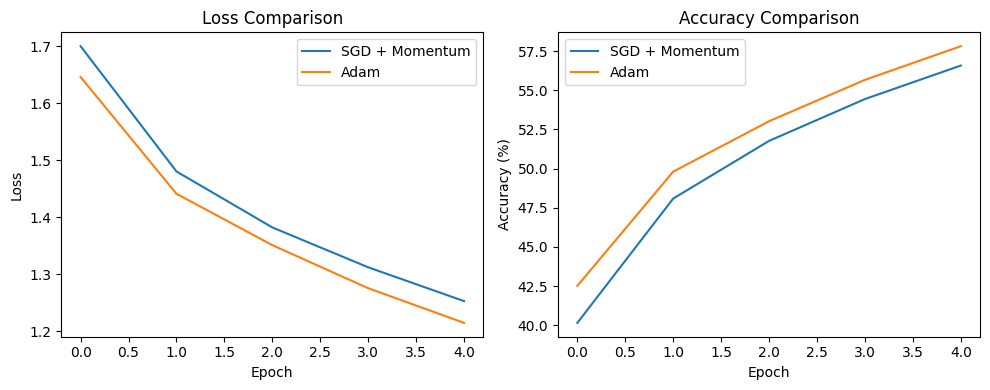

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

trainset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    transform=transform,
    download=True
)

trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=128,
    shuffle=True
)

class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            nn.Flatten(),
            nn.Linear(3 * 32 * 32, 256),
            nn.ReLU(),
            nn.Linear(256, 10)
        )

    def forward(self, x):
        return self.model(x)

def train(model, optimizer, epochs=5):
    model.to(device)
    loss_fn = nn.CrossEntropyLoss()

    losses = []
    accuracies = []

    for epoch in range(epochs):
        total_loss = 0
        correct = 0
        total = 0

        for images, labels in trainloader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = loss_fn(outputs, labels)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        avg_loss = total_loss / len(trainloader)
        accuracy = 100 * correct / total

        losses.append(avg_loss)
        accuracies.append(accuracy)

        print("Epoch:", epoch + 1,
              "Loss:", round(avg_loss, 4),
              "Accuracy:", round(accuracy, 2), "%")

    return losses, accuracies

print("SGD with Momentum")

model_sgd = MLP()
sgd = optim.SGD(
    model_sgd.parameters(),
    lr=0.01,
    momentum=0.9
)

loss_sgd, acc_sgd = train(model_sgd, sgd)

print("\nAdam Optimizer")

model_adam = MLP()
adam = optim.Adam(
    model_adam.parameters(),
    lr=0.001
)

loss_adam, acc_adam = train(model_adam, adam)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(loss_sgd, label="SGD + Momentum")
plt.plot(loss_adam, label="Adam")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss Comparison")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(acc_sgd, label="SGD + Momentum")
plt.plot(acc_adam, label="Adam")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Accuracy Comparison")
plt.legend()

plt.tight_layout()
plt.show()